In [ ]:
!pip install shap

In [ ]:
!pip install tensorflow

In [ ]:
!pip install openpyxl

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
import shap


data_train = pd.read_excel('train-22.xlsx', sheet_name='203', header=0)
data_test = pd.read_excel('test-22.xlsx', sheet_name='203', header=0)



feature_names = data_train.columns[2:28].tolist()  
print(feature_names)


X_train = data_train.iloc[:, 2:].values  
y_train = data_train.iloc[:, 1].values  


X_test = data_test.iloc[:, 2:].values  
y_test = data_test.iloc[:, 1].values  


# from sklearn.preprocessing import StandardScaler
# scaler = StandardScaler()
# X_train = scaler.fit_transform(X_train)
# X_test = scaler.transform(X_test)

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")


In [ ]:
!pip install matplotlib

In [ ]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score


model = joblib.load('mlr_model.pkl')


print(f"{model.n_features_in_}")
print(f"{X_train.shape[1]}")


X_train_corrected = X_train[:, :model.n_features_in_]  


# X_train_corrected = X_train.iloc[:, :model.n_features_in_]  


y_pred = model.predict(X_train_corrected)



plt.figure(figsize=(10, 6))
plt.plot(y_train, label='True', alpha=0.7)
plt.plot(y_pred, label='Predicted', alpha=0.7)
plt.xlabel('Sample')
plt.ylabel('Value')
plt.legend()
plt.title('True vs Predicted Values (Training Set)')
plt.show()


rmse = np.sqrt(mean_squared_error(y_train, y_pred))
r2 = r2_score(y_train, y_pred)



In [ ]:
#import matplotlib.pyplot as plt
#from sklearn.metrics import mean_squared_error, r2_score
#from keras.models import load_model
#import numpy as np
#model = tf.keras.models.load_model('model.h5')#('./best_model.keras')
#best_model = load_model('ak-tba.keras')

#print(model.summary())

In [ ]:

#from keras.models import load_model
#y_pred = model.predict(X_train)
#print(y_pred.shape)

#plt.plot(y_train, label='True')
#plt.plot(y_pred, label='Predicted')
#plt.xlabel('Sample')
#plt.ylabel('Value')
#plt.legend()
#plt.show()


#rmse =np.sqrt( mean_squared_error(y_train, y_pred))
#r2 = r2_score(y_train, y_pred)


#print('RMSE:', rmse)
#print('R2:', r2)


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np


import joblib  
model = joblib.load('mlr_model.pkl')  


print(f"{model.n_features_in_}")
print(f"{X_test.shape[1]}")

if X_test.shape[1] != model.n_features_in_:
 
    X_test_corrected = X_test[:, :model.n_features_in_]  
else:
    X_test_corrected = X_test


y_pred = model.predict(X_test_corrected)
print(y_pred.shape)


plt.plot(y_test, label='True')
plt.plot(y_pred, label='Predicted')
plt.xlabel('Sample')
plt.ylabel('Value')
plt.legend()
plt.show()


rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)



In [3]:



#shap.initjs()
#explainer = shap.KernelExplainer(model.predict, X_train)
#explainer = shap.Explainer(model, X_train)


#X = X_test[0:1].reshape(1, -1)

#shap_values = explainer.shap_values(X)
#shap_values = explainer(X_test[0:1])

import shap
import numpy as np
import matplotlib.pyplot as plt


if X_train.shape[1] != model.n_features_in_:
    X_train = X_train[:, :model.n_features_in_]
if X_test.shape[1] != model.n_features_in_:
    X_test = X_test[:, :model.n_features_in_]




explainer = shap.LinearExplainer(model, X_train)


shap_values = explainer.shap_values(X_test)  


shap.summary_plot(shap_values, X_test, 
                 feature_names=feature_names, 
                 show=False)


plt.savefig('shap_summary_custom_names.pdf', bbox_inches='tight', dpi=300)
plt.close()

In [ ]:
shap.force_plot(explainer.expected_value[0],  X_test[0:44,:], link="logit")

IndexError: invalid index to scalar variable.

In [ ]:
shap.plots.scatter(shap_values[:,:], color=shap_values)


TypeError: The shap_values parameter must be a shap.Explanation object!

In [ ]:
shap.plots.bar(shap_values)

TypeError: The shap_values argument must be an Explanation object, Cohorts object, or dictionary of Explanation objects!

In [ ]:
shap.force_plot(explainer.expected_value[0], shap_values[0], X_test, link="logit")

IndexError: invalid index to scalar variable.

In [ ]:
shap.plots.force(explainer.expected_value,shap_values.values,shap_values.data)

AttributeError: 'numpy.ndarray' object has no attribute 'values'

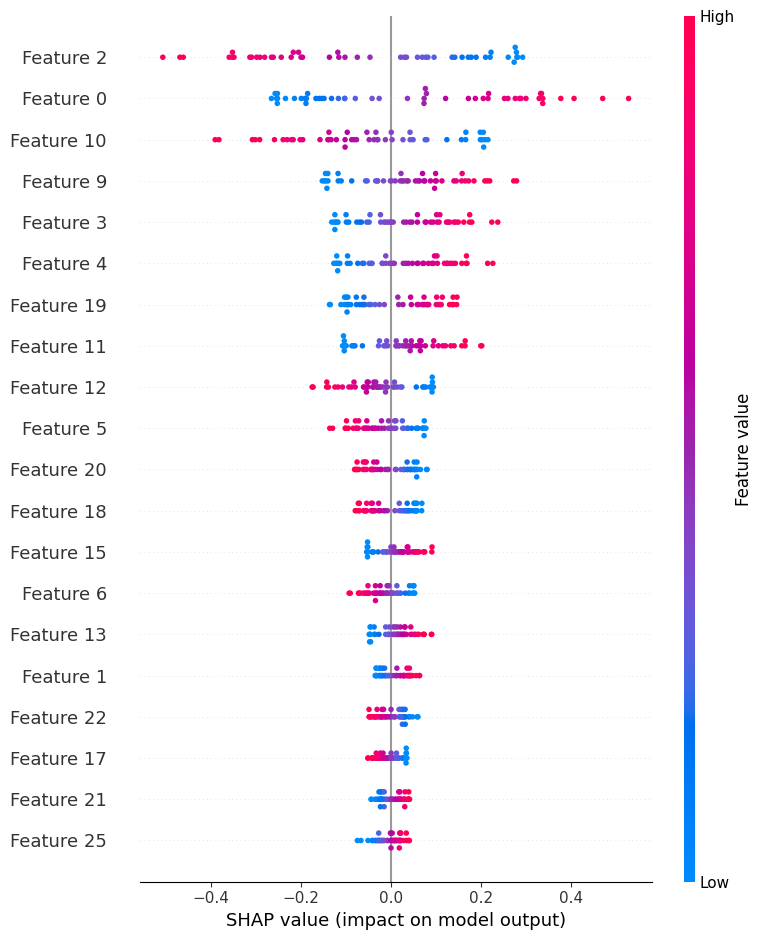

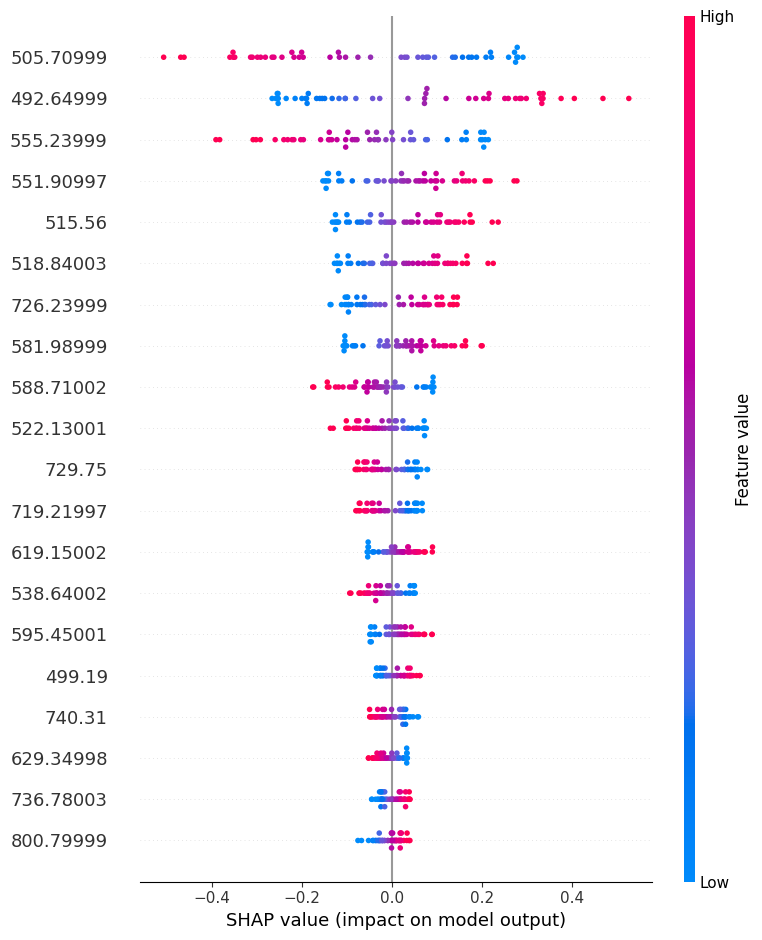

In [ ]:
shap.summary_plot(shap_values, X_test)
shap.summary_plot(shap_values, X_test, feature_names=feature_names)

shap.summary_plot(shap_values, X_test, feature_names=feature_names, show=False)
plt.savefig('shap_summary_plot111.png', bbox_inches='tight', dpi=300)
plt.close()

In [4]:
#X,y = shap.datasets.boston()
from sklearn.datasets import fetch_california_housing
import pandas as pd

california = fetch_california_housing()
X = pd.DataFrame(california.data, columns=california.feature_names)
y = california.target


In [ ]:
explainer = shap.Explainer(model, X_train)


In [ ]:
shap_values = explainer(X_test)


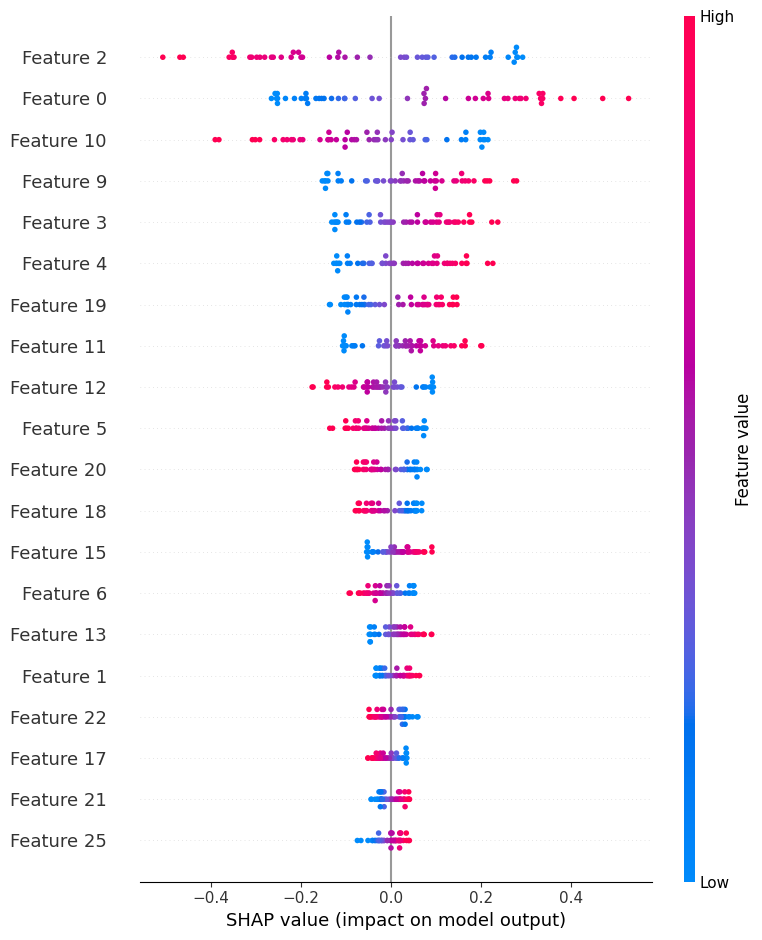

In [ ]:
shap.summary_plot(shap_values)

In [5]:

import matplotlib.pyplot as plt


shap.summary_plot(shap_values, X_test, show=False)

plt.savefig('1shap_summary_plot.pdf', 
           format='pdf', 
           bbox_inches='tight',  
           dpi=300)             


plt.savefig('1shap_summary_plot.png', bbox_inches='tight', dpi=150)

plt.close()  

In [ ]:
shap.initjs()
shap.plots.force(shap_values[0])


In [ ]:
shap.plots.force(shap_values)

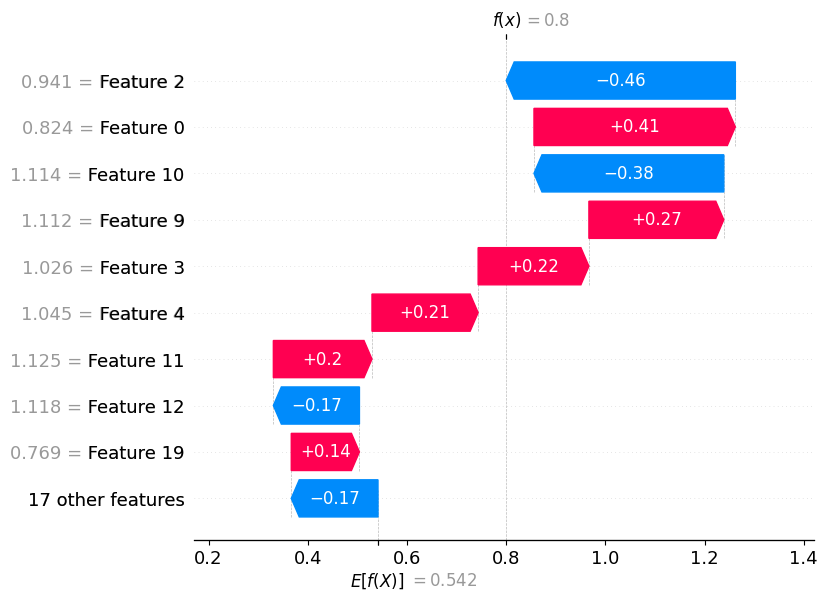

In [ ]:
shap.plots.waterfall(shap_values[0])


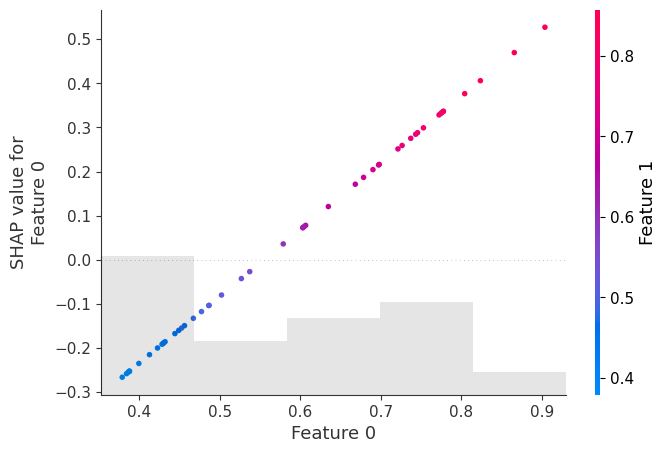

In [ ]:
shap.plots.scatter(shap_values[:,0], color=shap_values)


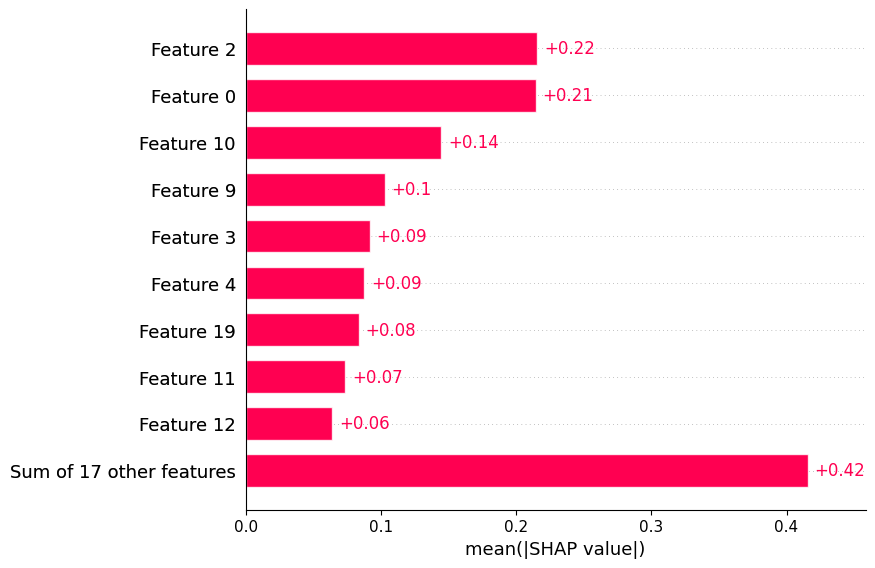

In [ ]:
shap.plots.bar(shap_values)


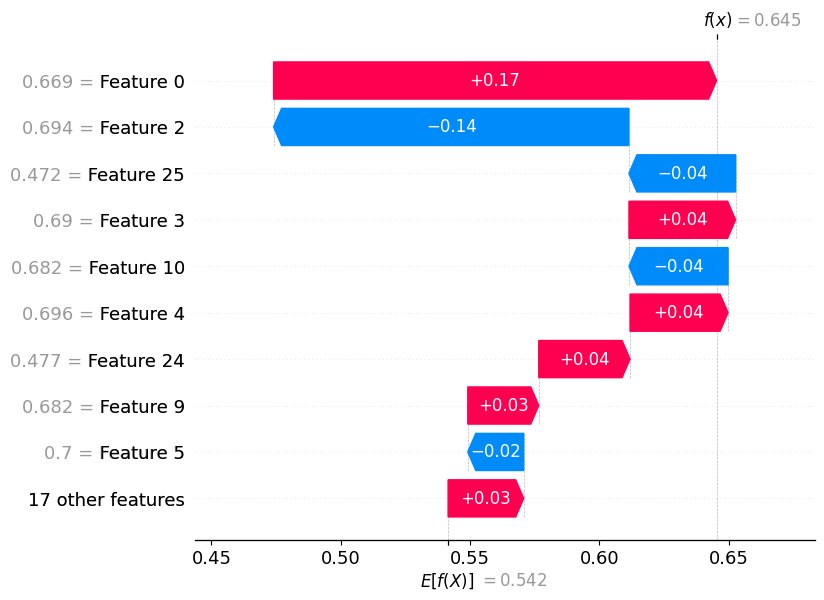

In [ ]:
shap.plots.waterfall(shap_values[1])

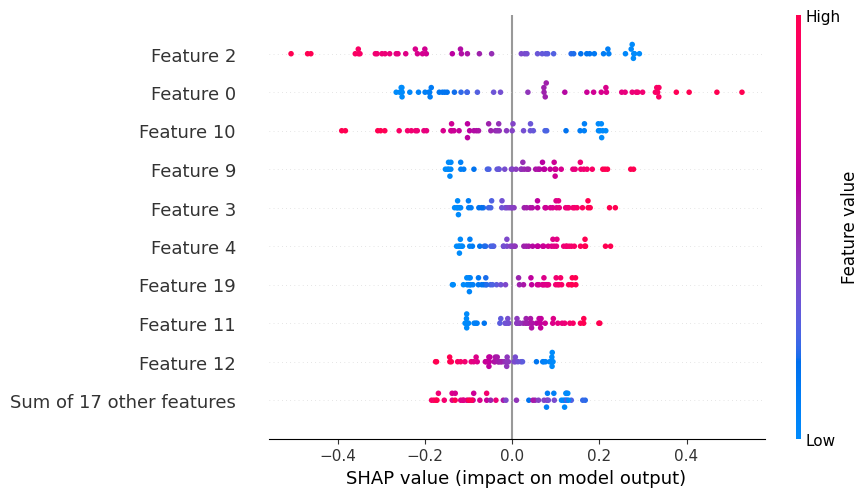

In [ ]:
# summarize the effects of all the features
shap.plots.beeswarm(shap_values)

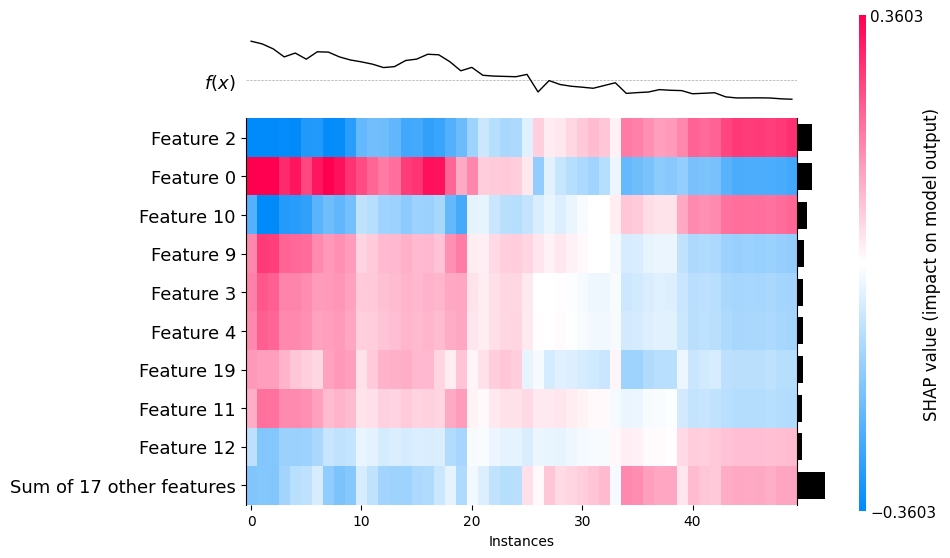

<Axes: xlabel='Instances'>

In [ ]:
shap.plots.heatmap(shap_values)